#Packages

ModuleNotFoundError: No module named 'tempnets'

### autocorrelation

We begin with autocorrelation of 1-d time series, and find the autocorrelation of both graph-based and topological statistics

$$ \frac{\sum_t (\gamma_t-\bar{\gamma})(\gamma_{t+\epsilon}-\bar{\gamma})}{\sum_t (\gamma_t - \bar{\gamma})^2}$$

If $\gamma$ doesn't vary, then this is equal to 1. If $\gamma$ alternates with respect to lag $ϵ$, this is -1.

The following function is meant for consecutive shapshots of the same temporal graph; in particular, G and H must have the same nodes. The function compares the adjacency matrices: for each vertex $i$, if any incident edge is present in both graphs (i.e. the network at timestep $t$ and $t+1$), then $\gamma[i]$ is defined to be the fraction of $st(i)$ that is present at both $t$ and $t+1$.

$$ \frac{A_i\cdot B_i}{\sqrt{|A_i||B_i|}}$$

### Topological persistence level

Instead of correlating the adjacency matrix, here we investigate the fraction of all features (all dimensions) at timesteps $t_1$ and $t_2$ that persist through the interval $(t_1,t_2)$, expressed as
$$ \frac{f_{12}}{\sqrt{f_1*f_2}} ,$$
where $f_1$ and $f_2$ are the betti numbers at times $t_1$ and $t_2$, respectively, and $f_{12}$ is the dimension of the submodule $PH^{t_1t_2}_{*}(N)$ persisting from $t_1$ to $t_2$.

##Stationarity

Next we examine topological stationarity. We test if topological autocorrelation through an interval $(t, t+w)$ depends on $t$, or if it depends only on $w$. We test the three distributions:


1.   $t\sim Unif(0,T)$
2.   $w$ in any distribution (we will integrate out)
3.   diagram autocorrelation $dac$ from $t$ to $t+w$

If $cov(t,dac)=0$, or sufficiently small, then we conclude the network is topologically stationary. If not, then there is a topological trend.





## Burstiness

To capture traditional burstiness, we measure the coefficient of variation for the intercontact times, and compare it to 1, as proposed in Goh and Barabasi.

To define a new measure of topological burstiness, we compute the coefficient of variation for the inter-birth and death times of all topological features. This gives a measure of whether topological changes happen in a cascading fashion, or if these shifts are temporally unrelated to each other.

*   Poisson processes have ```B = 0```
*   periodic sequences have ```B = -1```
*   the most bursty sequences have ```B = 1```

To measure topological burstiness, we consider the persistence of only those features dying before the end of the temporal sequence, as those surviving through $T$ have unknown persistence.

We define 3 different measures of burstiness


*   the coefficient of variation of pooled birth and death times
*   the coefficient of variation of persistence times
*   Separate coefficients of variation for inter-birth and inter-death in each dimension


Overwrite with birth and death times.

## Partitioning

By topological partitioning, we mean clustering timesteps of the network according to topological similarity. An obvious method would be to take all of the birth and death times as endpoints, and aggregate the networks in between; however, this may offer little to no compression.

Here we explore ways to use the persistence diagram to cluster timesteps less exactly: we'd like to identify intervals which preserve a maximal amount of features.

The ```persistence``` function, for times t1 and t2, counts the number of features of any dimension persisting through the (t1,t2) interval, and the number of topological changes happening inside the interval.

In [ ]:
nclust=5


In [ ]:
def cluster(dgms,T,nclust):
  # start with n-1 evenly spaced endpoints between 0 and T
  # for each interval, compute num features persisting and num topological changes
  # we'd like to minimize
  return

# Discrete temporal networks


Constructing classical instantaneous-time temporal networks, and the corresponding zigzag complex.

## Synthetics

In [ ]:
partition(tbin,[0,2])


    i  j  t  weight
0   0  5  0     1.0
1   0  8  0     1.0
2   1  9  0     1.0
3   2  7  0     1.0
4   3  5  0     1.0
.. .. .. ..     ...
4   3  4  1     1.0
5   3  5  1     1.0
6   3  7  1     1.0
7   6  9  1     1.0
8   7  8  1     1.0

[537 rows x 4 columns]


/usr/local/lib/python3.10/dist-packages/teneto/classes/network.py:242: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self.network['i'] = self.network['i'].astype(int)
/usr/local/lib/python3.10/dist-packages/teneto/classes/network.py:243: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self.network['j'] = self.network['j'].astype(int)


In [ ]:
tpoiss = TemporalNetwork()
tpoiss.generatenetwork('rand_poisson',nnodes=10,ncontacts=4,lam=8)
tpoiss.get_network_when(i=1)

,i,j,t
36,1,2,5
37,1,2,13
38,1,2,23
39,1,2,35
40,1,3,6
41,1,3,11
42,1,3,19
43,1,3,24
44,1,4,7
45,1,4,16


In [ ]:
sxs, times,time_bank = temp_net_to_clique_clx(tbin)
# flag function
zz,dgms,cell= d.zigzag_homology_persistence(d.Filtration(sxs),times)

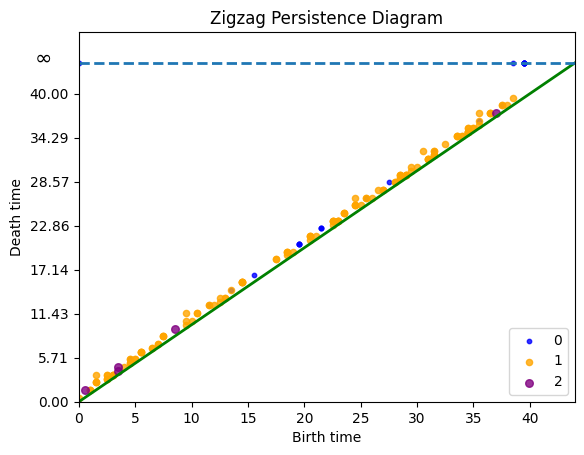

In [ ]:
plot_diags(dgms,tbin.T,rotate=False)

## Hospital data

In [ ]:
hosp = pd.read_csv("/content/detailed_list_of_contacts_Hospital.dat",delimiter = "\t",header=None)
hosp.columns = ['t','i','j','type1','type2']
hlist = hosp[['i','j','t']].values.tolist()
edgelist = hosp[['i','j']].values.tolist()
timespd = hosp.groupby(by=['i','j'])['t'].apply(list)
G = nx.Graph(edgelist)

time is in 20-sec intervals, so one day is 4320 time units.

In [ ]:
day=4320
hour = 180
minute = 3
T = np.max(hosp['t'])
spread = 2*hour
all_times = list(range(0,T+20,20))

We show that different buffer times result in the same topological statistics

In [ ]:
buffer_list = [minute,10*minute, hour, 4*hour, 10*hour, day, 2*day]
buffer = ["1 minute","10 minutes", "1 hour", "4 hours", "10 hours", "24 hours", "48 hours"]

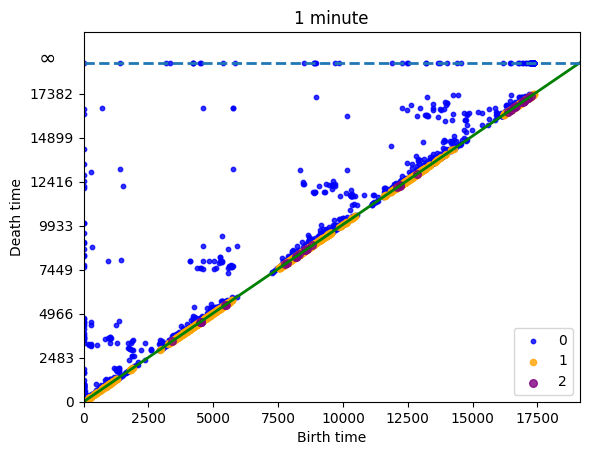

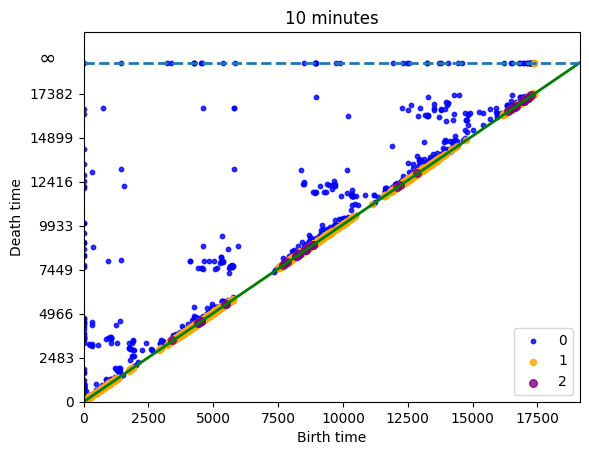

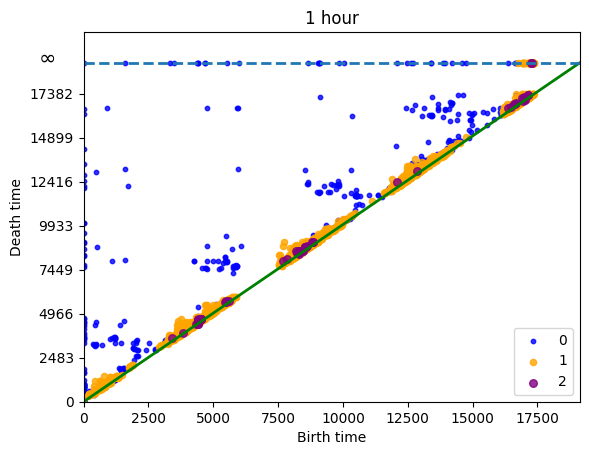

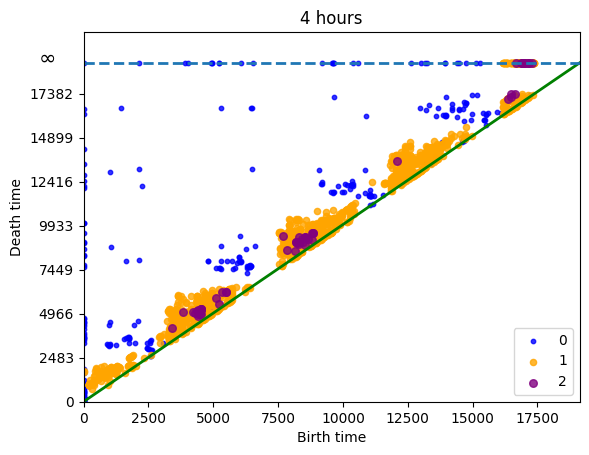

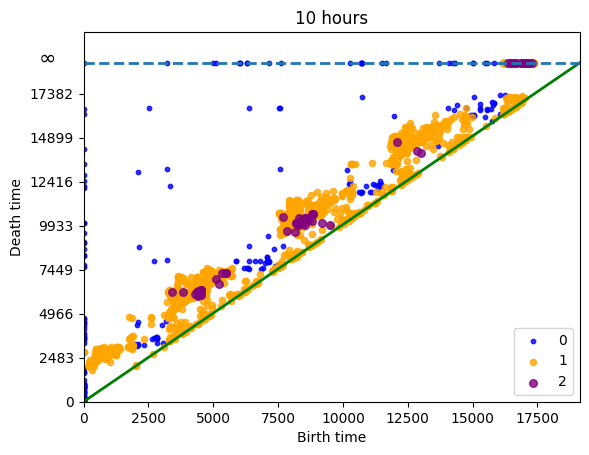

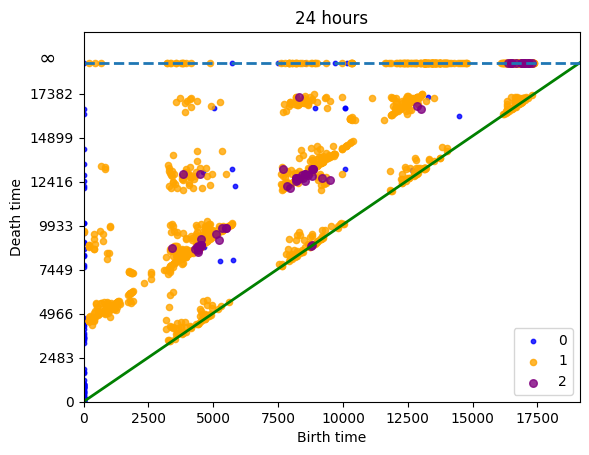

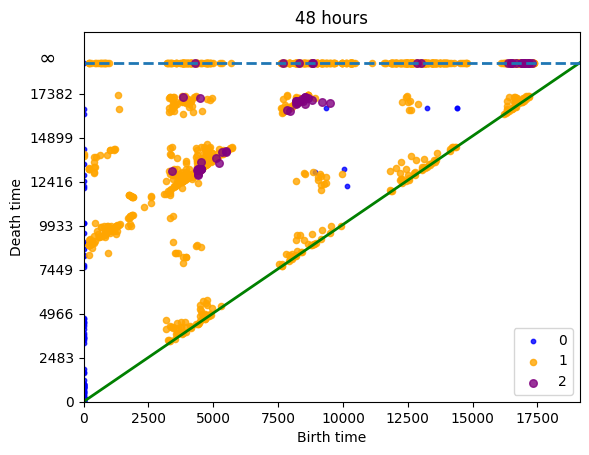

In [ ]:
hosp_dgm = []
hosp_graph_auto=[]
for j in range(len(buffer_list)):
  sxs = [[i] for i in G.nodes]
  timelist = [list(range(0,T,20)) for i in G.nodes]
  times = [[0,T] for i in G.nodes]
  for a,b in G.edges:
    if a < b:
      sxs.append([a,b])
    else:
      sxs.append([b,a])
    try:
      temp = timespd[a,b]
      timelist.append(temp)
      times.append(timelist_to_ee_non_int(temp,all_times,buffer=buffer_list[j]))
    except:
      temp = timespd[b,a]
      timelist.append(temp)
      times.append(timelist_to_ee_non_int(temp,all_times,buffer=buffer_list[j]))

  for sx in itertools.combinations(G.nodes,3):
      boundary1 = list(itertools.combinations(sx,2))
      if all([list(b) in sxs for b in boundary1]):
        time = set(timespd[boundary1[0]])
        for b in boundary1:
          time =  set.intersection(time,set(timespd[b]))
        if len(time)>0:
          sxs.append(list(sx))
          temp = sorted(list(time))
          timelist.append(temp)
          times.append(timelist_to_ee_non_int(temp,all_times,buffer=buffer_list[j]))

  fil = d.Filtration(sxs)
  zz,dgms,cell = d.zigzag_homology_persistence(fil,times)
  hosp_graph_auto.append(graph_autocorrelation(G,times,np.linspace(0, T)))
  hosp_dgm.append(dgms)
  plot_diags(dgms,T/20,title = buffer[j],save=buffer[j])

This one seems to be the bottleneck step because of list comprehension. The lists of entry-exit times are very long.

Topological autocorrelation is independent of buffer time

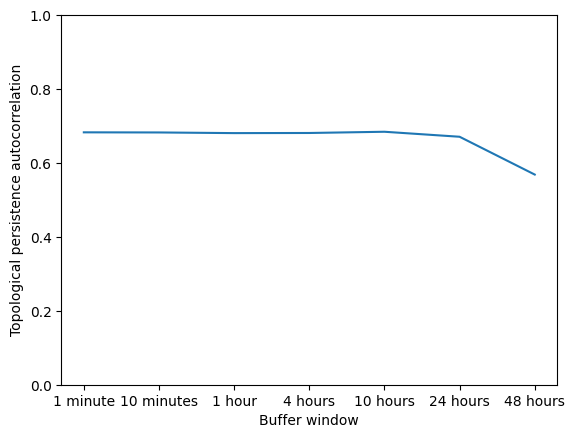

In [ ]:
auto_array = [top_autocorr(hosp_dgm[i],np.linspace(0, T),format='dionysus') for i in range(7)]
plt.plot(auto_array)
plt.ylim(0,1)
plt.xticks([0,1,2,3,4,5,6],labels=buffer)
plt.ylabel("Topological persistence autocorrelation")
plt.xlabel("Buffer window")
plt.show()

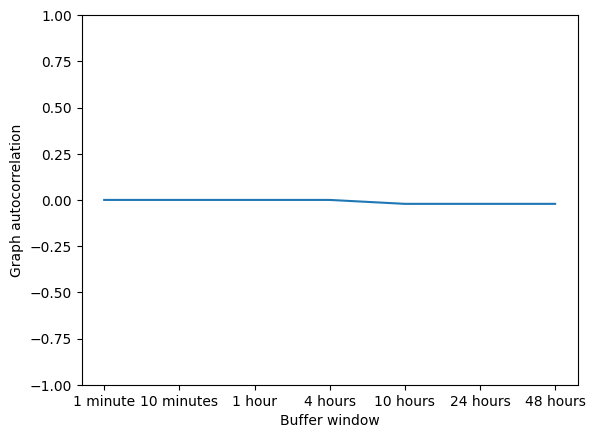

In [ ]:
plt.plot(hosp_graph_auto)
plt.ylim(-1,1)
plt.xticks([0,1,2,3,4,5,6],labels=buffer)
plt.ylabel("Graph autocorrelation")
plt.xlabel("Buffer window")
plt.show()

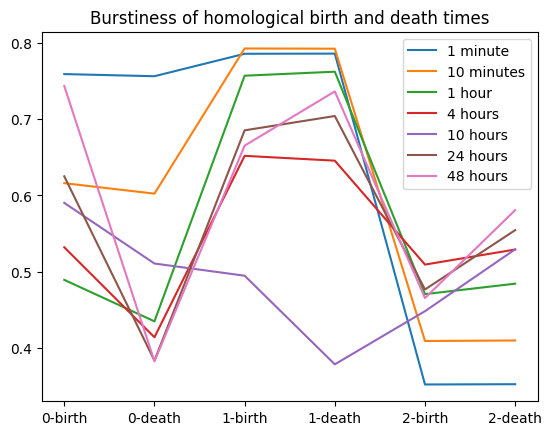

In [ ]:
burst = [top_burstiness(dg,T) for dg in hosp_dgm]
plt.plot(np.transpose(burst))
plt.xticks(range(6),labels=["0-birth", "0-death","1-birth","1-death","2-birth","2-death"])
plt.legend(labels=buffer)
plt.title("Burstiness of homological birth and death times")
plt.show()

#Contin. temporal networks

## Periodic Erdos-Renyi temporal network with poisson interval times

random graph class in zigzagclass.ipynb, with options for Erdos-Renyi, rewiring, periodic, bursty, poisson.

When $p=1$, we generate random periodic timesteps for the complete graph $K_n$.

In [ ]:
#Erdos-Renyi params
n = 20  #number of vertices
p = 0.5 #probability of edges

#periodic params
freq = 8 #time between appearances
l = 2   #how long edges stick around
T = 40  #total time period
max_dim=2

Choose edges with probability $p$, then if chosen, generate a random periodic sequence of timestamps

In [ ]:
net,sxs,times = ER_periodic(n,p,freq,l,T,max_dim)

In [ ]:
Y = d.Filtration(sxs)
dtimes = to_ee(times,sxs)
zz,dgms,cell=d.zigzag_homology_persistence(Y,dtimes)

Try this one a couple times to get a layout you like

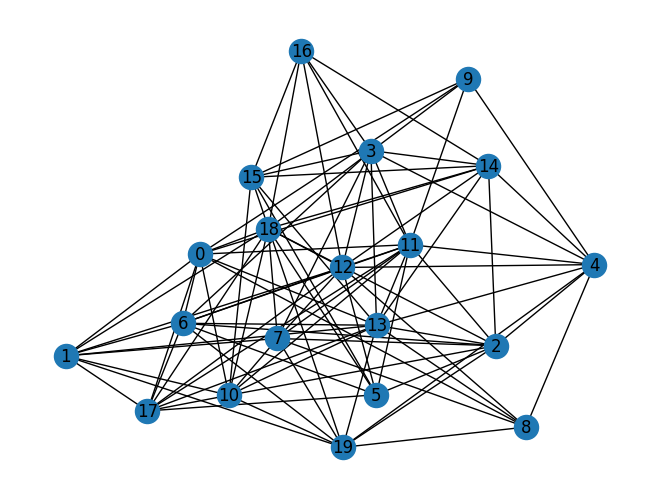

In [ ]:
layout = nx.drawing.layout.spring_layout(net,k=0.8)
nx.draw(net, pos = layout,with_labels=True)

Create a temporal graph and save animation to ```tempnet.gif```

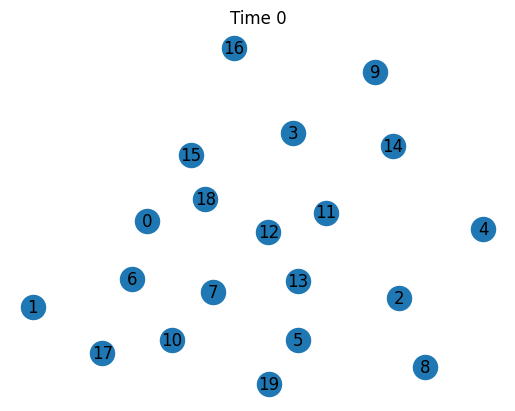

In [ ]:
fig, ax = plt.subplots()

def update(t):
  ax.clear()
  H = level_set(net,dtimes,t)
  nx.draw(H,layout,with_labels=True)
  for triangle in sxs:
    if len(triangle)==3:
      if is_in(times[(triangle[0],triangle[1],triangle[2])],t):
        points = [layout[vx] for vx in triangle]
        t1 = plt.Polygon(points,alpha=0.4)
        ax.add_patch(t1)
  ax.set_title("Time {}".format(int(t)))

ani = FuncAnimation(fig, update, frames=np.linspace(0, T, T*4))
ani.save('tempnet.gif',writer="pillow",fps=10)


This last bit takes some time depending on the size of the complex

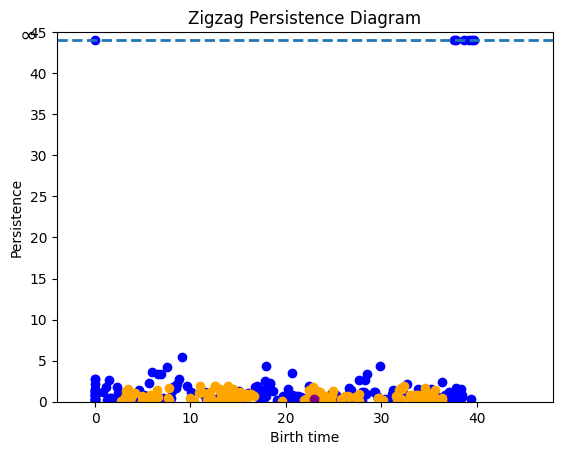

In [ ]:
plot_diags(dgms,T,rotate=True)

In [ ]:
T = 80
print(graph_autocorrelation(net,dtimes,np.linspace(0, T, T)))
print(top_autocorr(dgms,np.linspace(0, T, T),format='dionysus'))

0.8353945446800477
0.7501326205624702


## Watts-Strogatz with exponential rewiring

At exponential random intervals, we complete a rewiring

In [ ]:
n = 10
k= 3
p = 0
l = 2
T = 80

In [ ]:
G = nx.watts_strogatz_graph(n,k,p)
net,sxs,timesws = exponential_rewiring(G,l,T,max_dim=3)
Y = d.Filtration(sxs)
dtimes=to_ee(timesws,sxs)

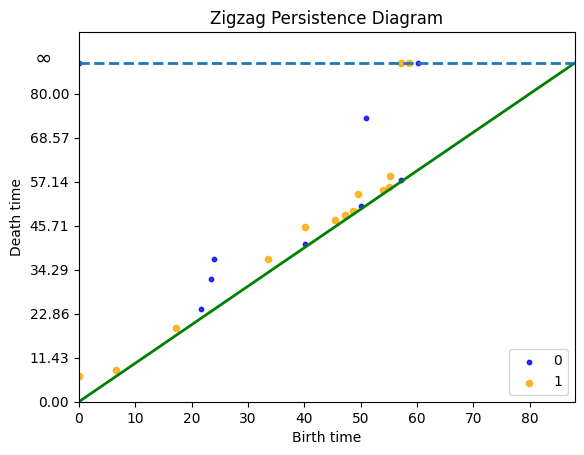

In [ ]:
zz,dgms,cell=d.zigzag_homology_persistence(Y,dtimes)
plot_diags(dgms,T)

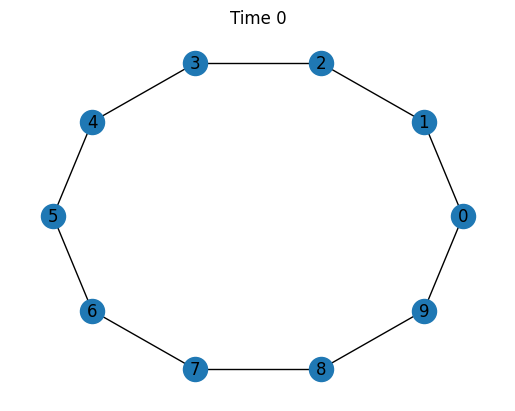

In [ ]:
layout = nx.drawing.layout.circular_layout(G)
fig, ax = plt.subplots()

def update(t):
  ax.clear()
  H = nx.Graph()
  H.add_nodes_from(G)
  for sx in sxs:
    if len(sx)==2:
      if is_in(timesws[(sx[0],sx[1])],t):
        H.add_edge(sx[0],sx[1])
    if len(sx)==3:
      if is_in(timesws[(sx[0],sx[1],sx[2])],t):
        points = [layout[pt] for pt in sx]
        t1 = plt.Polygon(points,alpha=0.4)
        ax.add_patch(t1)
  nx.draw(H,layout,with_labels=True)
  ax.set_title("Time {}".format(int(t)))


ani = FuncAnimation(fig, update, frames=np.linspace(0, T, T*4))
ani.save('tempnetws.gif',writer="pillow",fps=20)


## Topological models

Here we construct a temporal network with topological, but not other kinds, of periodicity

KNN of random points on circle, with different temporal dynamics

The following network class is topologically constant, with a constant degree sequence, but periodically recurring subgraphs. It features a cycle which expands

In [ ]:
n = 30
#num rays
r = 5
#rounds
k = 1
#length of rays
l = n/r
T = int(l * k)
sun = np.zeros(shape=(n,n,T))
for time in range(T):
  t = time%l
  for i in range(n):
    j = i%l
    if j ==1:
      sun[i,(i+1)%n,time] = 1
      sun[i,int((i-l+t)%n),time] = 1
    if 0<j and j < t+1:
      sun[i,(i+1)%n,time] = 1
    if j == t+1:
      sun[i,(i+1)%n,time] = 1
      sun[i,int((i+l-t)%n),time] = 1
    if j > t+1:
      sun[i,(i+1)%n,time] = 1
      sun[i,(i-1)%n,time] = 1
tsun = TemporalNetwork(from_array=sun)
#make sure to use union

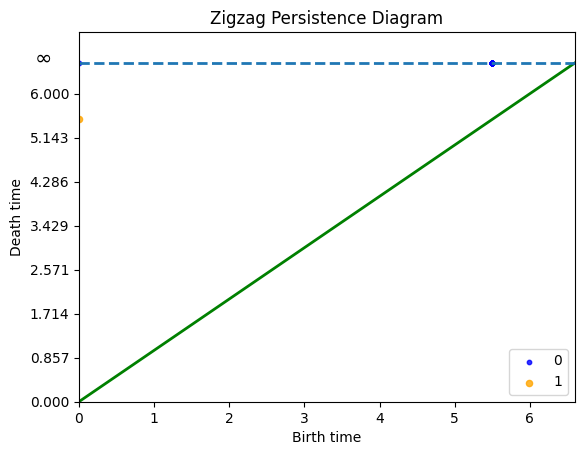

In [ ]:
sxs, times,time_bank = temp_net_to_clique_clx(tsun)
# flag function
zz,dgms,cell= d.zigzag_homology_persistence(d.Filtration(sxs),times)
plot_diags(dgms,T)

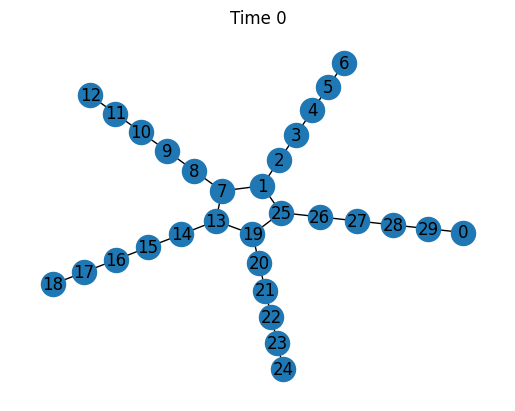

In [ ]:

fig, ax = plt.subplots()

def update(step):
  ax.clear()
  G = nx.from_pandas_edgelist(tsun.get_network_when(t=step),source='i',target='j')
  layout = nx.drawing.layout.kamada_kawai_layout(G)
  nx.draw(G,layout,with_labels=True)
  ax.set_title("Time {}".format(step))

ani = FuncAnimation(fig, update, frames=range(T))
ani.save('tempnetsun.gif',writer="pillow",fps=2)


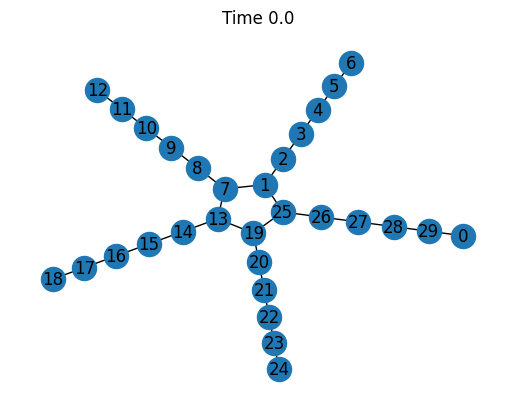

In [ ]:
dictimes = {tuple(i):j for i,j in zip(sxs,times)}
fig, ax = plt.subplots()

def update(step2):
  step=step2/2
  ax.clear()
  H = nx.Graph()
  H.add_nodes_from(G)
  for sx in sxs:
    if len(sx)==2:
      if is_in_ee(dictimes[(sx[0],sx[1])],step):
        H.add_edge(sx[0],sx[1])
    layout = nx.drawing.layout.kamada_kawai_layout(H)
    if len(sx)==3:
      if is_in_ee(dictimes[(sx[0],sx[1],sx[2])],step):
        points = [layout[pt] for pt in sx]
        t1 = plt.Polygon(points,alpha=0.4)
        ax.add_patch(t1)
  nx.draw(H,layout,with_labels=True)
  ax.set_title("Time {}".format(step))

ani = FuncAnimation(fig, update, frames=range(0,2*T))
ani.save('tempnetsun.gif',writer="pillow",fps=2)

Here we have a random graph (uniform on edges) that is topologically self-inhibiting.

In [ ]:
n=10
p=0.25
T=40
l = T/10
G = nx.gnp_random_graph(n,p)

In [ ]:
def remove_a_loop(G):
  try:
    edges = nx.simple_cycles(G)
    edge = np.random.randint(0,len(edges))
    (s,t) = edges[edge]
    G.remove_edge(s,t)
    return (s,t)
  except:
    return None

In [ ]:
def add_rand_edge(G):
  n = G.number_of_nodes()
  u = np.random.randint(n)
  v = np.random.randint(n)
  while u==v:
    v=np.random.randint(n)
  if G.has_edge(u,v) or G.has_edge(v,u):
    return add_rand_edge(G)
  else:
    G.add_edge(min(u,v),max(u,v))
    return (min(u,v),max(u,v))

In [ ]:
def remove_rand_edge(G):
  to_remove = random.sample(G.edges(),k=1)
  G.remove_edges_from(to_remove)
  return to_remove[0]

This is the basic building function

In [ ]:
def topological_rewiring(net,l,T,max_dim=2):
    sxs = []
    for i in range(n):
      sxs.append([i])
    times = {}
    for edge in net.edges():
      times[edge] = [(0,T)]
    t = int(np.random.exponential(l)*1000)/1000
    num = len(net.edges())
    G = net.copy()
    while t < T:
      edge = remove_a_loop(G)
      if edge==None:
        (a,b) = remove_rand_edge(G)
      else:
        a = edge[0]
        b = edge[1]
      recent = times[(a,b)][-1]
      times[(a,b)][-1] = (recent[0],t)

      (u,v) = add_rand_edge(G)
      if (u,v) in times.keys():
        if times[(u,v)][-1][1]==T:
          print(str((u,v)) + "bad bad no good")
        times[(u,v)].append((t,T))
      else:
        times[(u,v)] =[(t,T)]
      t = int((t + np.random.exponential(l))*1000)/1000
    for edge in times.keys():
      sxs.append(list(edge))
      G.add_edge(edge[0],edge[1])
#      for (t0,t1) in times[edge]:
#        X.add(t0,t1,[edge[0],edge[1]])
#    X = flag(X,times,max_dim=max_dim)

    for i in range(2,max_dim+1):
      possible = list(itertools.combinations(range(n),i+1))
      for sx in possible:
        boundary1 = list(itertools.combinations(sx,2))
        if all([list(b) in sxs for b in boundary1]):
          time = intersection([times[b] for b in boundary1])
          if len(time)>0:
            sxs.append(list(sx))
            times[sx] = time

    return G,sxs,times

In [ ]:
net,sxs,times = topological_rewiring(G,2,T)

<ipython-input-67-b814483e1096>:2: DeprecationWarning: Sampling from a set deprecated
since Python 3.9 and will be removed in a subsequent version.
  to_remove = random.sample(G.edges(),k=1)


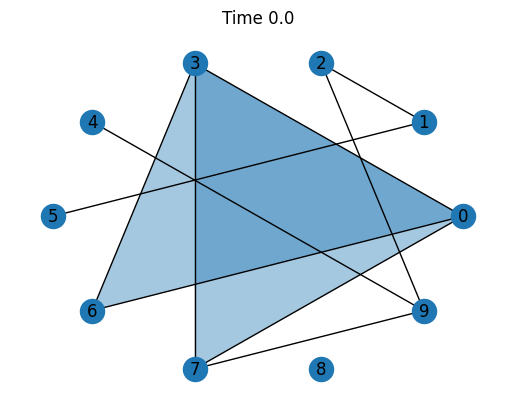

In [ ]:
fig, ax = plt.subplots()

def update(step2):
  step=step2/2
  ax.clear()
  H = nx.Graph()
  H.add_nodes_from(net)
  layout = nx.drawing.layout.kamada_kawai_layout(H)
  for sx in sxs:
    if len(sx)==2:
      if is_in(times[(sx[0],sx[1])],step):
        H.add_edge(sx[0],sx[1])
    if len(sx)==3:
      if is_in(times[(sx[0],sx[1],sx[2])],step):
        points = [layout[pt] for pt in sx]
        t1 = plt.Polygon(points,alpha=0.4)
        ax.add_patch(t1)
  nx.draw(H,layout,with_labels=True)
  ax.set_title("Time {}".format(step))

ani = FuncAnimation(fig, update, frames=range(0,2*T))
ani.save('selfinhibit.gif',writer="pillow",fps=l)

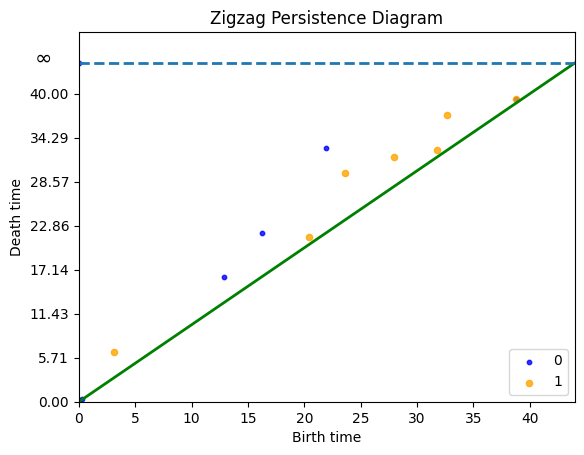

In [ ]:
zz,dgms,cell= d.zigzag_homology_persistence(d.Filtration(sxs),to_ee(times,sxs))
plot_diags(dgms,T)

# Comparison Tests

Comparing adjacency and topological autocorrelation

In [ ]:
adjacency = []
topo = []
bursty_cv = []
topo_cv = []
for i in range(50):
  n = 10
  p = 0.5
  freq = 8
  l = 2
  T = 50
  net,X,times = ER_periodic(n,p,freq,l,T,max_dim=1)
  bursty_cv.append(burstiness(times))
  #all_K = X.complex().get_simplices()
  all_K = X
  Y = d.Filtration(all_K)
  dtimes=to_ee(times,all_K)
  zz,dgms,cell=d.zigzag_homology_persistence(Y,dtimes)
  all_finite_pers = []
  for i,dgm in enumerate(dgms):
    newpers = []
    for feat in dgm:
      if feat.death < T:
        newpers.append(feat.death-feat.birth)
    all_finite_pers.append(newpers)
  B = cv(all_finite_pers[0]+all_finite_pers[1])
  topo_cv.append(B)
  adjacency.append(graph_autocorrelation(net,dtimes,np.linspace(0, T, T)))
  topo.append(top_autocorr(dgms,np.linspace(0, T, T),format='dionysus'))

Text(0.5, 1.0, 'Experiment 1, ER periodic')

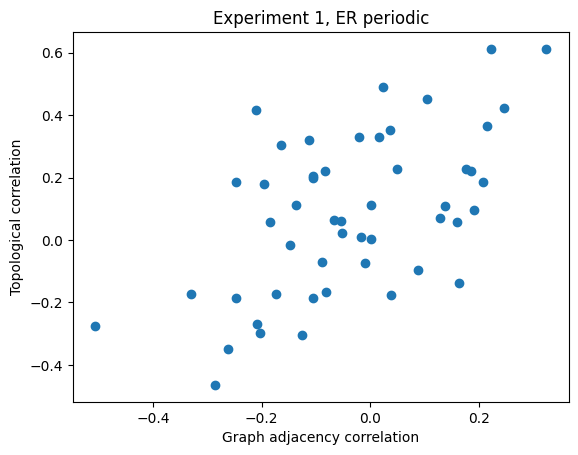

In [ ]:
plt.scatter(adjacency,topo)
plt.xlabel("Graph adjacency correlation")
plt.ylabel("Topological correlation")
plt.title("Experiment 1, ER periodic")

Compare burstiness and topological burstiness

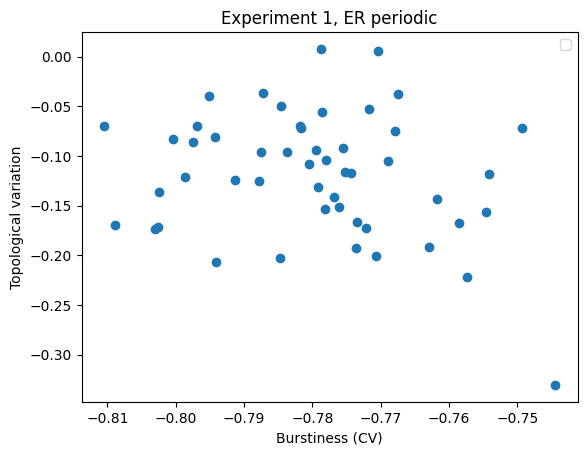

In [ ]:
plt.scatter(bursty_cv,topo_cv)
plt.xlabel("Burstiness (CV)")
plt.ylabel("Topological variation")
plt.title("Experiment 1, ER periodic")
plt.legend()
plt.show()

Compare burstiness of different models

Compare stationarity of different models

Compare TPL of different models

## Randomized reference models and topological tests of significance

We begin with a temporal network TN, and construct a randomized reference model. We analyze the zigzag homology of various samples generated from the model, and compare with the homology of T.

In [ ]:
TN = TemporalNetwork()
TN.generatenetwork('rand_poisson',nnodes=15,ncontacts=3)

In [ ]:
arr = teneto.generatenetwork.rand_binomial([10,10,15], [0.25, 0.80])
G = TemporalNetwork(from_array = arr)

In [ ]:
G.network.shape

(10, 10, 15)

This function randomizes the time stamps of a teneto Temporal Network

In [ ]:
def scrambly(tempnet):
  #random permutation vector
  n = tempnet.T
  perm = np.array(range(n))
  perm = np.random.permutation(perm)
  edges = np.array(tempnet.network) #columns i j t weight
  newnet = TemporalNetwork()
  for i in range(len(edges)):
    edge = edges[i,:]
    t = edge[2]
    print(t)
    edge[2] = perm[int(t)]
    newnet.add_edge(edge)
  return newnet

In [ ]:
def scrambly_arr(tempnet):
  n = tempnet.T
  perm = np.array(range(n))
  perm = np.random.permutation(perm)
  network = tempnet.network
  new_net = np.zeros(shape = network.shape)
  for i in range(n):
    new_net[:,:,i] = network[:,:,perm[i]]
  return TemporalNetwork(from_array = new_net)


In [ ]:
n = 20
#input = tsun
input = G
rref = [input]
sxs, times,time_bank = temp_net_to_clique_clx(input)
simplices = [sxs]
eelist = [times]
# flag function
zz,dgms,cell= d.zigzag_homology_persistence(d.Filtration(sxs),times)
results = [dgms]
for i in range(1,n):
#  rref.append(scrambly(input))
  rref.append(scrambly_arr(input))
  sxs, times,time_bank = temp_net_to_clique_clx(rref[i])
  simplices.append(sxs)
  eelist.append(times)
# flag function
  zz,dgms,cell= d.zigzag_homology_persistence(d.Filtration(sxs),times)
  results.append(dgms)

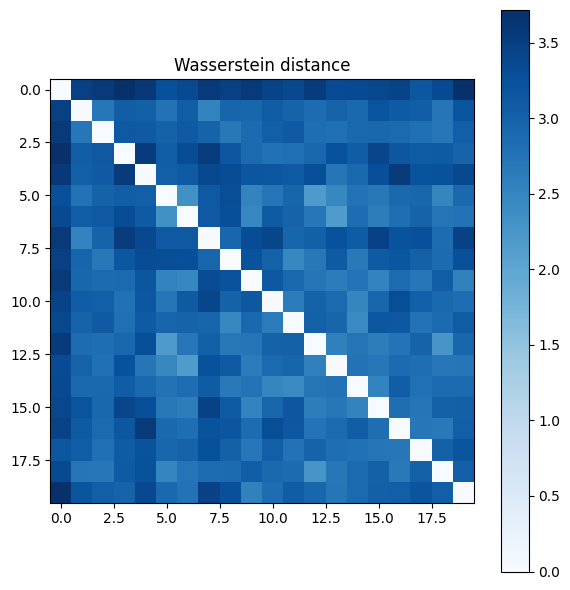

In [ ]:

inds = range(n)
corrdist = [[d.wasserstein_distance(results[key][1],results[key1][1]) for key1 in inds] for key in inds]

c = 0

#fig,ax1 = plt.subplots(1,n,figsize = (15,5))
#plotspace = range(n)
#for i in range(len(corrdist)):
#  ax = ax1[plotspace[i]]
  # ax.scatter(trial_names,wassdist[i],
  #            label = lab[:-1]+'% trial '+lab[-1],
  #            s = 150,edgecolor ='k' )
  # ax.legend()
  # ax.set_ylabel('Wassterstein Distance')
#  c+=1
# plt.show()

%matplotlib inline
fig,ax0 = plt.subplots(1, figsize = (6,6))
ax=ax0
ec = ax.imshow(corrdist,cmap='Blues')
#ax.set_xticks(list(range(n)))
#ax.set_yticks(list(range(n)))
#ax.set_xticklabels(labels)
#ax.set_yticklabels(labels)
#ax.set_xticklabels(labels, Rotation=45)
cbar = plt.colorbar(ec)
ax.set_title('Wasserstein distance')
plt.tight_layout()
plt.show()

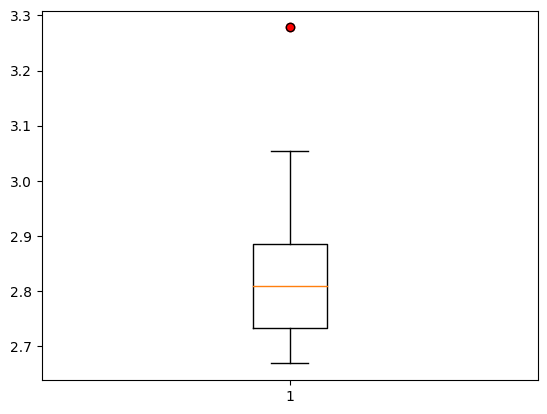

In [ ]:
means = [np.mean(corrdist[i]) for i in range(n)]
plt.boxplot(means)
plt.scatter(1,means[0],color='red')

In [ ]:
original = means[0]
sort_means = sorted(means[1:])
rank = 1
for i in range(1,len(sort_means)-1):
  if original > sort_means[-i]:
    rank = i
    break
  else : i= i+1
print("There are "+str(rank-1)+" out of "+str(n)+ " random reference networks further from the mean than the input.")
if (rank-1)/n <= 0.05:
  print("Input network has significantly different topology.")
else:
  print("Input network does not have significantly different topology.")

There are 0 out of 20 random reference networks further from the mean than the input.
Input network has significantly different topology.


Test hospital network against RREF

Test rewiring against RREF

# Clustering

In this section we use the matrix of Wasserstein distances to cluster.

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage,average
from scipy.spatial.distance import squareform

In [ ]:
hier_tree = average(squareform(corrdist))

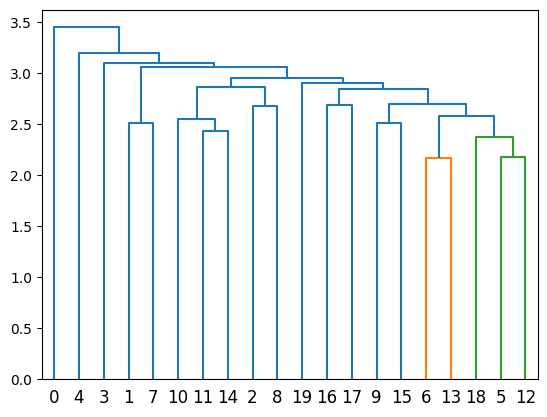

In [ ]:
dn = dendrogram(hier_tree)
plt.show()